In [3]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8')

In [4]:
#Step-1 Generate the Data

X, y = make_regression()
print(X.shape, y.shape)

(100, 100) (100,)


In [5]:
X,Y=make_regression(n_samples=500,n_features=10,n_informative=5,noise=2,random_state=0)
print(X.shape, Y.shape)
n_features=X.shape[1]

(500, 10) (500,)


In [6]:
pd.DataFrame(X)

,0,1,2,3,4,5,6,7,8,9
0,1.706468,1.511639,-0.000417,0.374155,0.073285,0.701783,0.409552,-0.461894,-0.626490,-0.799593
1,-1.616956,0.640132,-0.369182,-0.239379,-0.738031,-0.024326,1.099660,0.279925,-0.098150,0.655264
2,0.093953,-0.130107,0.929505,0.582225,-2.739677,0.943046,-2.094603,-0.569312,0.269904,0.123722
3,-1.542758,-0.789954,0.537035,-0.286835,-2.369623,-0.767332,1.634406,-0.260560,0.128957,0.571227
4,-0.101003,-2.231538,0.436187,1.571463,1.324868,-0.587375,1.077315,0.840648,0.261106,0.811090
...,...,...,...,...,...,...,...,...,...,...
495,-1.263173,-0.340692,-0.780304,0.271113,1.151734,-2.777359,1.045023,-0.589229,-0.448465,0.599040
496,-0.307132,-0.522579,0.022213,0.543453,0.490971,-0.449037,0.139988,0.865525,1.274045,-0.344046
497,-1.791328,-0.365055,-0.499017,0.021351,-0.317543,-0.058587,-0.919113,-1.632423,-0.067134,0.192754
498,-0.360084,-1.126841,0.624447,0.054561,-0.670759,-0.349691,0.452399,-0.956580,0.597939,1.614796


In [7]:
pd.DataFrame(X).head()

,0,1,2,3,4,5,6,7,8,9
0,1.706468,1.511639,-0.000417,0.374155,0.073285,0.701783,0.409552,-0.461894,-0.626490,-0.799593
1,-1.616956,0.640132,-0.369182,-0.239379,-0.738031,-0.024326,1.099660,0.279925,-0.098150,0.655264
2,0.093953,-0.130107,0.929505,0.582225,-2.739677,0.943046,-2.094603,-0.569312,0.269904,0.123722
3,-1.542758,-0.789954,0.537035,-0.286835,-2.369623,-0.767332,1.634406,-0.260560,0.128957,0.571227
4,-0.101003,-2.231538,0.436187,1.571463,1.324868,-0.587375,1.077315,0.840648,0.261106,0.811090


In [8]:
#Step-2 Normalise
def normalise(X):
    u=X.mean(axis=0)
    std=X.std(axis=0)

    return (X-u)/std

In [9]:
X=normalise(X)
pd.DataFrame(X).head()

,0,1,2,3,4,5,6,7,8,9
0,1.764831,1.579606,0.093808,0.341546,0.103202,0.745205,0.421736,-0.461091,-0.710885,-0.761760
1,-1.612963,0.709920,-0.277540,-0.301827,-0.693297,-0.045695,1.116862,0.265971,-0.166048,0.714702
2,0.125936,-0.058708,1.030243,0.559735,-2.658385,1.007996,-2.100631,-0.566372,0.213499,0.175267
3,-1.537551,-0.717175,0.635024,-0.351591,-2.295090,-0.855000,1.655498,-0.263762,0.068151,0.629417
4,-0.072209,-2.155744,0.533470,1.597083,1.331926,-0.658985,1.094355,0.815541,0.204426,0.872842


In [10]:
X.mean(axis=0)

array([-2.75335310e-17,  5.82867088e-17, -1.06581410e-17, -1.39888101e-17,
        2.49800181e-18,  4.28546088e-17,  1.43635104e-17,  1.46549439e-17,
        7.14983628e-17, -1.07691633e-16])

In [11]:
X.std(axis=0)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

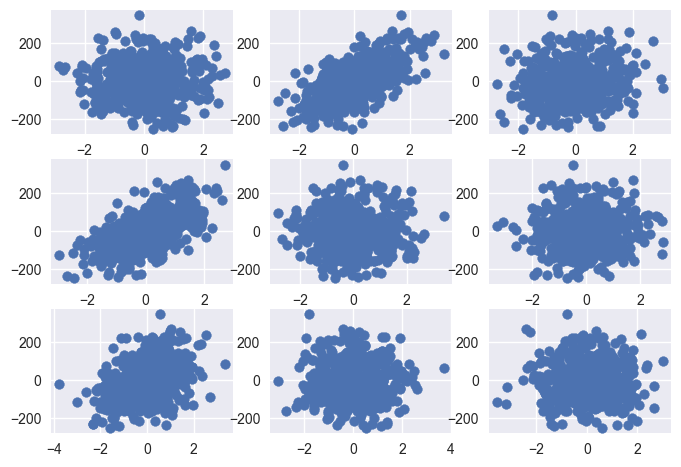

In [12]:
#Step-3:Visualize y as function of each feature

for f in range(0,9):
    plt.subplot(3,3,f+1)
    plt.scatter(X[:,f],Y)
plt.show()

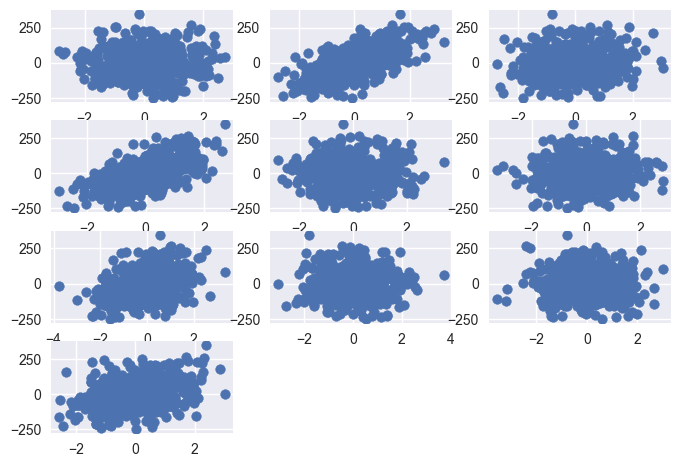

In [13]:
for f in range(0,10):
    plt.subplot(4,3,f+1)
    plt.scatter(X[:,f],Y)
plt.show()

In [14]:
#Step-4:Train Test Split
XT,Xt,YT,Yt=train_test_split(X,Y,test_size=0.3,shuffle=False,random_state=0)

In [15]:
print(XT.shape,YT.shape)
print(Xt.shape,Yt.shape)

(350, 10) (350,)
(150, 10) (150,)


In [16]:
#Step-5:Modelling

def preprocess(X):
    if X.shape[1] == n_features:
        m=X.shape[0]
        ones=np.ones((m,1))
        X=np.hstack((ones,X))
    return X


def hypothesis(X,theta):
    return np.dot(X,theta)

def loss(X,Y,theta):
    yp=hypothesis(X,theta)
    error=np.mean((yp-Y)**2)
    return error

def gradient(X,y,theta):
    yp=hypothesis(X,theta)
    m=X.shape[0]
    grad=np.dot(X.T,(yp-y))
    return grad/m

def train(X,Y,lr=0.1,maxTers=100):
    n=X.shape[1]
    theta= np.random.randn(n)
    error_list=[]

    for i in range(maxTers):
        err=loss(X,Y,theta)
        error_list.append(err)
        grad=gradient(X,Y,theta)
        theta=theta-lr*grad

    plt.plot(error_list)
    return theta



(350, 11) (150, 11)
[-3.83053417e+00 -2.12851135e-02  6.04370468e+01  1.06953625e+01
  6.35757191e+01 -3.57722148e-02  7.46727912e-02  4.09262388e+01
  4.12740866e-02  6.09090327e-02  2.53392271e+01]


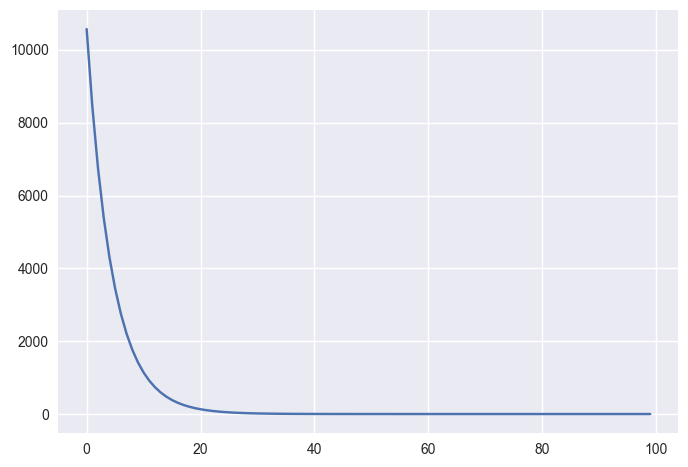

In [17]:
XT=preprocess(XT)
Xt=preprocess(Xt)
print(XT.shape,Xt.shape)

theta=train(XT,YT)
print(theta)

In [18]:
pd.DataFrame(XT).head()

,0,1,2,3,4,5,6,7,8,9,10
0,1.0,1.764831,1.579606,0.093808,0.341546,0.103202,0.745205,0.421736,-0.461091,-0.710885,-0.761760
1,1.0,-1.612963,0.709920,-0.277540,-0.301827,-0.693297,-0.045695,1.116862,0.265971,-0.166048,0.714702
2,1.0,0.125936,-0.058708,1.030243,0.559735,-2.658385,1.007996,-2.100631,-0.566372,0.213499,0.175267
3,1.0,-1.537551,-0.717175,0.635024,-0.351591,-2.295090,-0.855000,1.655498,-0.263762,0.068151,0.629417
4,1.0,-0.072209,-2.155744,0.533470,1.597083,1.331926,-0.658985,1.094355,0.815541,0.204426,0.872842


In [19]:
#Evaluation
def R2SCORE(Y,yp):
    ymean=Y.mean()
    num=np.sum((Y-yp)**2)
    denom=np.sum((y-ymean)**2)
    return (1 - num/denom) * 100

In [20]:
yp=hypothesis(Xt,theta)

In [21]:
gradient(XT,YT,theta)

array([ 0.00034807, -0.00064452, -0.00038839, -0.00157957, -0.0032105 ,
        0.0011794 ,  0.00155491, -0.00266957, -0.00074117,  0.00199148,
        0.00176049])

In [22]:
gradient(XT,YT,theta).shape

(11,)

In [23]:
print(Xt.shape)

(150, 11)


In [24]:
R2SCORE(Yt,yp)

99.97596238443948

In [25]:
#With Sklearn
from sklearn.linear_model import LinearRegression

In [26]:
model= LinearRegression()
model.fit(Xt,Yt)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [27]:
yp.shape

(150,)

In [29]:
model.predict(Xt)

array([-1.07823159e+02, -6.46426531e+01,  1.47456033e+02,  6.04661262e+00,
        2.17007023e+02,  1.09642586e+02, -3.89039093e-01,  1.15181731e+02,
       -1.42662713e+02,  8.59607485e+01, -3.41896686e+01, -3.34623429e+00,
       -4.39958472e+01, -2.24396268e+01, -2.33277822e+01,  1.80267285e+01,
       -1.25938139e+01, -4.75502269e+01, -1.46512478e+02, -5.63093528e+01,
       -5.06157831e+01, -4.75183294e+01, -4.33394567e+01, -2.48387466e+02,
       -9.75449975e+01, -5.96331756e+00,  1.29845949e+02,  5.50342609e+00,
        1.12730793e+01, -6.00008481e+01,  7.27995649e+01,  3.89945766e+01,
        1.34387297e+02,  8.01787186e+01,  1.66731520e+02,  2.00873327e+01,
       -1.61161340e+02, -6.33416745e+00,  8.68399819e+01, -1.03815607e+02,
        3.41600393e+01,  1.06015207e+02, -2.73751445e+01,  1.09541619e+02,
       -4.62791403e+01, -2.30469030e+01, -1.96147767e+01, -3.73616506e+01,
       -1.13984709e+02,  1.31383466e+02,  8.25056845e+01,  1.96240822e+02,
       -1.08542815e+01, -

In [30]:
model.score(Xt,Yt)

0.9996123835006603

In [31]:
model.intercept_

-3.58126610240858

In [32]:
model.coef_

array([ 0.        , -0.08921176, 60.34277143, 10.32987073, 63.5374715 ,
       -0.12312066, -0.15755709, 40.96044427, -0.07853365,  0.18854176,
       25.36481655])

In [33]:
model.coef_.shape

(11,)